---
title: "Lecture 10: Covariance and Correlation, Conditional Expectation and Variance"
author: "Jamie Haddock"
format:
    revealjs:
        output-file: Lecture10_slides
        slide-number: true
        preview-links: auto
        logo: figs/hmc.png
        css: input/slides.css
        incremental: true
        smaller: true
        code-fold: true
        embed-resources: true
        html-math-method: katex
        slide-level: 3
    html:
        code-fold: true
        embed-resources: true
        output-file: Lecture10
        code-links:
          - text: "Open in Colab"
            href: "https://colab.research.google.com/github/jamiehadd/Math-151-Probability/blob/main/10_covariance-correlation-conditional-expectation-variance.ipynb"
            icon: "laptop"
    pdf:
        documentclass: article
        toc: true
        number-sections: true
        output-file: Lecture10
        geometry:
          - top=1in
          - left=1in
          - bottom=1in
          - right=1in
format-links: false
jupyter: python3
colab:
  gh-user: "jamiehadd"
  gh-repo: "Math-151-Probability"
filters:
  - input/remove-pause.lua
  - colab
execute:
  echo: true
  eval: true
---

# Covariance and Correlation

## Covariance

$$\text{Cov}(X,Y) = E[(X-E[X])(Y-E[Y])] = E[XY] - E[X]E[Y]$$

::: {.callout-note}
## Definition: uncorrelated
$X$ and $Y$ are **uncorrelated** if $\text{Cov}(X,Y) = 0$.
:::

::: {.callout-tip}
## Facts
- $\text{Cov}(X,X) = \text{Var}(X)$
- $\text{Cov}(X, aY+b) = a\,\text{Cov}(X,Y)$
- $\text{Cov}(X, Y+Z) = \text{Cov}(X,Y) + \text{Cov}(X,Z)$
- $X,Y$ independent $\implies \text{Cov}(X,Y) = 0$ (the converse is **false** -- next slide)
:::


### Example: Uncorrelated but Not Independent

$(X,Y)$ uniform over the four points $(1,0), (0,1), (-1,0), (0,-1)$
(each with probability $\tfrac14$)

. . .

$\text{Cov}(X,Y) = E[XY] - E[X]E[Y] = 0 - 0\dot 0 = 0$

. . .

However, $X$ and $Y$ are not independent since a nonzero value of $X$ fixes $Y = 0$ and vice versa.

## Correlation

$$\rho(X,Y) = \frac{\text{Cov}(X,Y)}{\sqrt{\text{var}(X)\text{var}(Y)}} \in [-1, 1]$$

$\rho$ rescales covariance to be unit-free: $\rho$ near $+1$ means a
strong positive linear relationship, near $-1$ a strong negative one,
near $0$ little to no linear relationship.

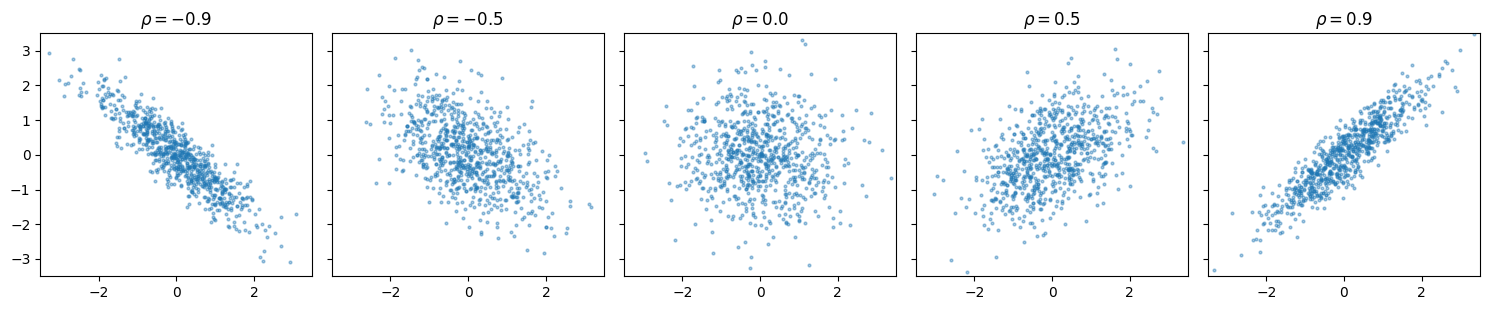

In [3]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(1)
rhos = [-0.9, -0.5, 0.0, 0.5, 0.9]

fig, axes = plt.subplots(1, len(rhos), figsize=(15, 3.2), sharex=True, sharey=True)
for ax, r in zip(axes, rhos):
    cov_mat = [[1, r], [r, 1]]
    samples = rng.multivariate_normal([0, 0], cov_mat, 800)
    ax.scatter(samples[:, 0], samples[:, 1], s=4, alpha=0.4, color="C0")
    ax.set_title(fr"$\rho = {r}$")
    ax.set_xlim(-3.5, 3.5)
    ax.set_ylim(-3.5, 3.5)

plt.tight_layout()
plt.show()

### Example: Heads and Tails out of $n$ Flips

$X$ = # heads, $Y$ = # tails out of $n$ independent flips. Since
$X + Y = n$ and $E[X] + E[Y] = n$, we have $$X - E[X] = -(Y - E[Y]).$$

. . .

Thus, $$\text{Cov}(X,Y) = E\left[(X-E[X])(Y-E[Y])\right] = -E\left[(X-E[X])^2\right] = -\text{var}(X).$$

. . .

And, $$\rho(X,Y) = \frac{-\text{var}(X)}{\sqrt{\text{var}(X)^2}} = -1.$$

::: {.callout-tip}
## Fact
$\rho = 1$ or $-1$ $\iff$ $Y - E[Y] = c\,(X - E[X])$ for some constant $c$
(a perfect linear relationship). Here $c=-1$.
:::

## Variance of a Sum of RVs

$$\text{Var}\Big(\sum_i X_i\Big) = \sum_i \text{Var}(X_i) + \sum_{i \ne j} \text{Cov}(X_i, X_j)$$

<details>
<summary>Proof</summary>

$$\text{Var}\Big(\sum_i X_i\Big) = E\Big[\Big(\sum_i (X_i - EX_i)\Big)^2\Big]
= \sum_i \sum_j E[(X_i-EX_i)(X_j-EX_j)]$$
Splitting the double sum into $i=j$ and $i \ne j$ terms gives
$\sum_i \text{Var}(X_i) + \sum_{i\ne j}\text{Cov}(X_i,X_j)$. (The second
sum is over *ordered* pairs, so it's the same as $2\sum_{i<j}\text{Cov}(X_i,X_j)$.)
</details>

. . .

If all pairs are uncorrelated (in particular if the $X_i$ are
independent), every covariance term vanishes and this collapses to the
familiar $\text{Var}(\sum_i X_i) = \sum_i \text{Var}(X_i)$.

### Example: The Hat-Check Problem, Revisited

Recall the previous example: $n$ people's hats are shuffled and returned at
random; $X$ = number of people who get their own hat back, $X=\sum_i X_i$
where $X_i$ indicates person $i$ getting their own hat. We showed
$E[X]=1$ for every $n$. Now: $\text{Var}(X)$?

. . .

Because $X_i$ is Bernoulli with parameter $p = 1/n$, we have
$$\text{Var}(X_i) = \tfrac1n - \tfrac1{n^2} = \tfrac{n-1}{n^2} \text{  and  } E[X_i] = 1/n,$$

. . .

so 
$$
\begin{aligned}
\text{Cov}(X_i,X_j) &= E[X_iX_j] - \frac{1}{n} \frac{1}{n} = P(X_i =1, X_j =1) - \frac{1}{n^2}
\\&= P(X_i = 1)P(X_j = 1 \mid X_i = 1) - \frac{1}{n^2} = \tfrac{1}{n(n-1)} - \tfrac1{n^2} = \tfrac{1}{n^2(n-1)} \;\; (i\ne j)
\end{aligned}
$$

. . .

Thus,

$$\text{Var}(X) = n\cdot\frac{n-1}{n^2} + n(n-1)\cdot\frac{1}{n^2(n-1)}
= \frac{n-1}{n} + \frac1n = 1$$

**$\text{Var}(X) = 1$ for every $n \ge 2$**.

# Conditional Expectation & Variance

## Law of Iterated Expectation

$E[X\,|\,Y]$ is itself a **random variable**: its value depends on the
outcome of $Y$. $E[X\,|\,Y{=}y]$ is an ordinary function of $y$;
plugging in the random $Y$ makes $E[X\,|\,Y]$ random too.

::: {.callout-tip}
## Law of Iterated Expectation (LIE)
$$E\big[E[X\,|\,Y]\big] = E[X]$$
:::

### Example: Random Coin Bias

A coin's probability of heads $Y$ is itself random ($Y \sim \text{Uniform}(0,1)$).
Given $Y=y$, the number of heads $X$ in $n$ flips is
$\text{Binomial}(n,y)$. What is $E[X]$?

$$E[X\,|\,Y] = nY \quad\Longrightarrow\quad
E[X] = E[nY] = n\,E[Y] = \frac n2$$

### Example: Averaging Quiz Scores by Section

A class has $n$ students and the $i$th student's quiz score is $x_i$, with the class's average $$m = \frac{1}{n} \sum_{i=1}^n x_i.$$  The students are divided into $k$ disjoint sections $A_1, \cdots, A_k$ and section $A_i$ has $n_i$ students.  The average score in section $i$ is $$m_i = \frac{1}{n_i} \sum_{i \in A_i} x_i.$$

. . .

The average over the whole class can be computed as a weighted average of the section averages: $$\sum_{s=1}^k \frac{n_s}{n} m_s = \sum_{s=1}^k \frac{n_s}{n} \frac{1}{n_s} \sum_{i \in A_s} x_i = \frac{1}{n} \sum_{s=1}^k \sum_{i \in A_s} x_i = m.$$

---

We can see this same calculation through the conditional expectation lens: 

. . .

Consider an experiment where a student is selected uniformly at random.  Consider $X$ to be the quiz score of the student, and $Y$ to be the section of the student.  

. . .

We have $E[X] = m$ and $E[X \mid Y = s] = m_s$, then $$m = E[X] = E[E[X\mid Y]] = \sum_{s=1}^k E[X\mid Y=s] P(Y = s) = \sum_{s=1}^k \frac{n_s}{n} m_s.$$

## Conditional Expectation as an Estimator

Write $\hat X = E[X\,|\,Y]$ (the estimator) and $\tilde X = X - \hat X$
(the estimation error), so $X = \hat X + \tilde X$.

::: {.callout-tip}
## Facts
- **Estimator is unbiased:** $E[\tilde X] = E[X] - E[\hat X] = E[X]-E[X] = 0$ (by LIE).
- **Uncorrelated with the error:** $\text{Cov}(\hat X, \tilde X) = 0$, since
  conditioning on $Y=y$ makes $\hat X$ a constant and $E[\tilde X\,|\,Y{=}y]=0$.
- Consequently $\text{Var}(X) = \text{Var}(\hat X) + \text{Var}(\tilde X)$.
:::

---

The picture: $\hat X(y)$ is the conditional-mean curve; $\tilde X$ is the
scatter of points around it, and that scatter is -- on average --
unrelated to where you are on the curve.

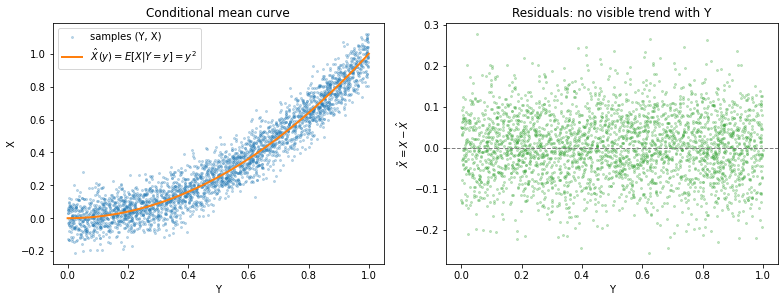

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(6)

def draw(n):
    Y = rng.uniform(0, 1, n)
    Xhat = Y**2                               # conditional mean E[X|Y=y] = y^2
    X = rng.normal(Xhat, 0.08, n)             # X | Y=y ~ N(y^2, 0.08^2)
    return Y, Xhat, X, X - Xhat

# a modest sample for a readable scatter plot...
Y, Xhat, X, Xtilde = draw(3000)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))

yy = np.linspace(0, 1, 200)
axes[0].scatter(Y, X, s=4, alpha=0.25, color="C0", label="samples (Y, X)")
axes[0].plot(yy, yy**2, color="C1", lw=2, label=r"$\hat X(y) = E[X|Y=y] = y^2$")
axes[0].set_xlabel("Y")
axes[0].set_ylabel("X")
axes[0].legend()
axes[0].set_title("Conditional mean curve")

axes[1].scatter(Y, Xtilde, s=4, alpha=0.25, color="C2")
axes[1].axhline(0, color="gray", ls="--", lw=1)
axes[1].set_xlabel("Y")
axes[1].set_ylabel(r"$\tilde X = X - \hat X$")
axes[1].set_title("Residuals: no visible trend with Y")

plt.tight_layout()
plt.show()


## Conditional Variance

We now define the random variable
$$\text{Var}(X\,|\,Y) = E\left[(X - E[X\mid Y])^2 \mid Y\right] = E[\tilde{X}^2 \mid Y].$$

::: {.callout-tip}
## Law of Total Variance
$$\text{Var}(X) = E\big[\text{Var}(X\,|\,Y)\big] + \text{Var}\big(E[X\,|\,Y]\big)$$
:::

<details>
<summary>Derivation</summary>

This is exactly the previous slide's decomposition
$\text{Var}(X)=\text{Var}(\hat X)+\text{Var}(\tilde X)$, rewritten: the
"estimator variance" term $\text{Var}(\hat X) = \text{Var}(E[X|Y])$ is the
**between-group** variance, and the "error variance" term
$\text{Var}(\tilde X) = E[\text{Var}(X|Y)]$ is the **within-group**
variance, since $E[\tilde X^2\,|\,Y{=}y] = \text{Var}(X\,|\,Y{=}y)$
(the conditional mean of $\tilde X$ given $Y=y$ is $0$).
</details>

### Example: Biased-Coin Example, Variance

Continuing the random-bias coin: with $Y\sim\text{Uniform}(0,1)$,
$X\,|\,Y=y \sim \text{Binomial}(n,y)$,
$$
\begin{aligned}
E[\text{Var}(X|Y)] &= E[nY(1-Y)] = n(E[Y] - \text{Var}(Y) - (E[Y])^2) = n\Big(\tfrac12-\tfrac{1}{12} - \tfrac{1}{4}\Big) 
\\&= \frac n6
\end{aligned}
$$

. . .

Then, 
$$\text{Var}(E[X|Y]) = \text{Var}(nY) = n^2 \cdot \tfrac1{12}$$

. . .

and,
$$\text{Var}(X) = \frac n6 + \frac{n^2}{12} = \frac{n(n+2)}{12}.$$